# Principal Component Analysis (PCA) – Hands-on Lab

**Level:** Introductory to intermediate  
**Goal:** Understand how PCA reduces the number of features while retaining as much variation in the data as possible.

It follows the core PCA workflow: standardize numerical features, calculate principal components, inspect explained variance, transform the data, and visualize the result.

> PCA is an unsupervised dimensionality-reduction technique. It does not use the target labels when learning the components. We use labels later only to color the visualization and discuss what information PCA preserves or loses.


## 1. What is PCA?

Principal Component Analysis (PCA) transforms a set of possibly correlated features into a smaller set of new features called **principal components**.

- **PC1** captures the largest possible amount of variation in the data.
- **PC2** captures the largest remaining variation, while being perpendicular (uncorrelated in the PCA representation) to PC1.
- Later components capture progressively less variation.

### Why use PCA?
- Reduce the number of dimensions.
- Visualize high-dimensional data in 2D or 3D.
- Reduce redundancy from correlated features.
- Potentially reduce noise and computational cost.

### Important intuition

Imagine a dataset with height and weight. These two features may be correlated. PCA can rotate the coordinate system so that the first component captures the direction of greatest variation.

PCA does **not** select the original best features. It creates new features as combinations of the original ones.


In [1]:
# Import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

%matplotlib inline


## 2. Load a dataset

We will use the built-in **Wine dataset** from scikit-learn. It contains 13 numerical chemical measurements for wine samples and a class label identifying one of three wine cultivars.

We will use the 13 measurements for PCA. The class label is not used to fit PCA.


In [2]:
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print("Dataset shape:", X.shape)
print("Number of classes:", y.nunique())
display(X.head())
print("\nClass names:", list(wine.target_names))


Dataset shape: (178, 13)
Number of classes: 3


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Class names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


## 3. Explore feature scales

PCA is sensitive to feature scale because it looks for directions of maximum variance. A feature measured in large numerical units can dominate the components.

First inspect the feature ranges. Then standardize the features so each has mean 0 and standard deviation 1.


In [3]:
display(X.describe().T[["mean", "std", "min", "max"]])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
display(scaled_df.head())
print("Scaled feature means (approximately 0):")
print(np.round(X_scaled.mean(axis=0), 3))
print("Scaled feature standard deviations (approximately 1):")
print(np.round(X_scaled.std(axis=0), 3))


,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


Scaled feature means (approximately 0):
[-0. -0. -0. -0. -0.  0. -0.  0. -0.  0.  0.  0. -0.]
Scaled feature standard deviations (approximately 1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 4. Fit PCA and inspect explained variance

Start by fitting PCA with all 13 components. This lets us see how much variance each component explains.

**Explained variance ratio** tells us the proportion of the dataset's total variation captured by each component.


In [4]:
pca_all = PCA()
X_pca_all = pca_all.fit_transform(X_scaled)

variance_table = pd.DataFrame({
    "Principal Component": [f"PC{i+1}" for i in range(len(pca_all.explained_variance_ratio_))],
    "Explained Variance Ratio": pca_all.explained_variance_ratio_,
    "Cumulative Explained Variance": np.cumsum(pca_all.explained_variance_ratio_)
})
display(variance_table.round(4))


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.3620,0.3620
1,PC2,0.1921,0.5541
2,PC3,0.1112,0.6653
3,PC4,0.0707,0.7360
4,PC5,0.0656,0.8016
5,PC6,0.0494,0.8510
6,PC7,0.0424,0.8934
7,PC8,0.0268,0.9202
8,PC9,0.0222,0.9424
9,PC10,0.0193,0.9617


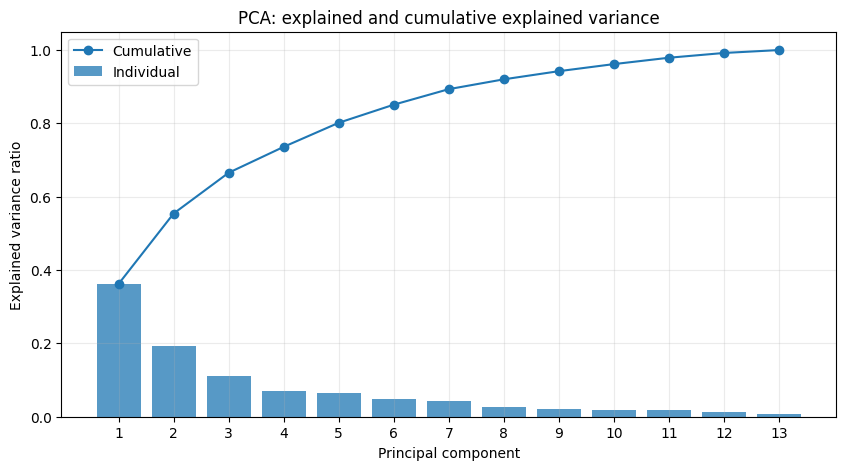

In [5]:
plt.figure(figsize=(10, 5))
components = np.arange(1, len(pca_all.explained_variance_ratio_) + 1)
plt.bar(components, pca_all.explained_variance_ratio_, alpha=0.75, label="Individual")
plt.plot(components, np.cumsum(pca_all.explained_variance_ratio_), marker="o",
         label="Cumulative")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA: explained and cumulative explained variance")
plt.xticks(components)
plt.grid(alpha=0.25)
plt.legend()
plt.show()


### Think about it

1. Which component explains the most variance?
2. How many components are needed to retain at least 90% of the variance?
3. If we keep only two components, how much information (in terms of variance) is retained?

The cumulative explained variance curve helps make the dimensionality decision. There is no universal rule that 90% or 95% is always the correct threshold; the choice depends on the use case.


## 5. Reduce 13 features to 2 principal components

Now retain only two components. This reduces the feature space from 13 dimensions to 2 dimensions, making it possible to visualize the samples on a scatter plot.


In [6]:
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca_2, columns=["PC1", "PC2"])
pca_df["Wine class"] = y.values

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca_2.shape)
print("Variance retained by 2 components:",
      round(pca_2.explained_variance_ratio_.sum() * 100, 2), "%")
display(pca_df.head())


Original shape: (178, 13)
Reduced shape: (178, 2)
Variance retained by 2 components: 55.41 %


,PC1,PC2,Wine class
0,3.316751,1.443463,0
1,2.209465,-0.333393,0
2,2.516740,1.031151,0
3,3.757066,2.756372,0
4,1.008908,0.869831,0


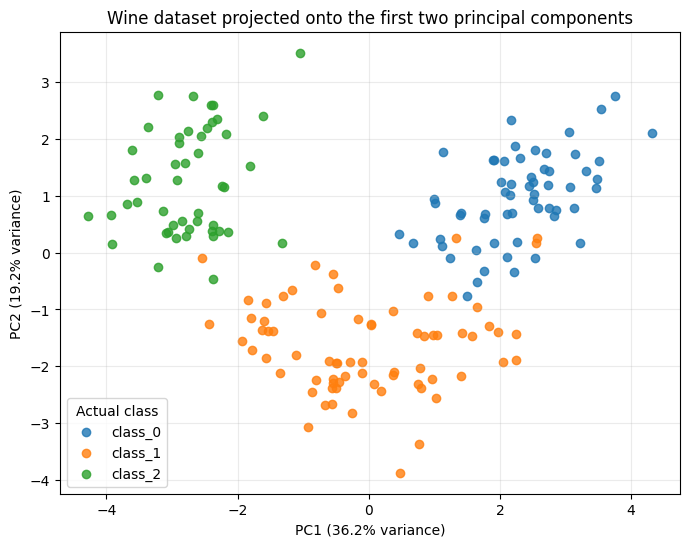

In [7]:
plt.figure(figsize=(8, 6))
for class_id, class_name in enumerate(wine.target_names):
    subset = pca_df[pca_df["Wine class"] == class_id]
    plt.scatter(subset["PC1"], subset["PC2"], label=class_name, alpha=0.8)

plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Wine dataset projected onto the first two principal components")
plt.legend(title="Actual class")
plt.grid(alpha=0.25)
plt.show()


**Interpretation:** Each dot is one wine sample. PCA created the horizontal and vertical axes from combinations of the original 13 measurements. The colors show the known class labels only to help us inspect whether the projection reveals class structure.

If groups overlap, it does not necessarily mean PCA failed. PCA maximizes overall variance, not class separation.


## 6. Understand the principal component loadings

A principal component is a weighted combination of the original standardized features. The weights are called **loadings** (the entries of the component vectors).

Large absolute loading values indicate features that contribute more strongly to that component. The sign indicates direction; flipping all signs of a component would represent the same axis.


In [9]:
loadings = pd.DataFrame(
    pca_2.components_.T,
    index=X.columns,
    columns=["PC1 loading", "PC2 loading"]
)
display(loadings.sort_values("PC1 loading", key=np.abs, ascending=False).round(3))


,PC1 loading,PC2 loading
flavanoids,0.423,-0.003
total_phenols,0.395,0.065
od280/od315_of_diluted_wines,0.376,-0.164
proanthocyanins,0.313,0.039
nonflavanoid_phenols,-0.299,0.029
hue,0.297,-0.279
proline,0.287,0.365
malic_acid,-0.245,0.225
alcalinity_of_ash,-0.239,-0.011
alcohol,0.144,0.484


### Discussion

- Which original features have the largest absolute loadings on PC1?
- Which features contribute strongly to PC2?
- Why might it be difficult to give a simple business meaning to a principal component?

Remember: a component combines several original variables. PCA can improve compactness, but the transformed features may be less interpretable.


## 7. Compare PCA before and after scaling

This experiment demonstrates why standardization is usually important when features use different units or have very different variances.


In [10]:
pca_unscaled = PCA(n_components=2)
pca_unscaled.fit(X)

pca_scaled = PCA(n_components=2)
pca_scaled.fit(X_scaled)

comparison = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Unscaled variance ratio": pca_unscaled.explained_variance_ratio_,
    "Scaled variance ratio": pca_scaled.explained_variance_ratio_
})
display(comparison.round(4))


,Component,Unscaled variance ratio,Scaled variance ratio
0,PC1,0.9981,0.3620
1,PC2,0.0017,0.1921


**Question:** Why can PCA on unscaled data be dominated by a feature with a large numerical range?

**Expected idea:** PCA is variance-based. A feature with a much larger scale can contribute disproportionately to total variance. Standardization puts features on a comparable scale. However, scaling is not automatic in every problem: if the original units and variance differences are meaningful, the choice should be considered deliberately.


## 8. Optional: Use PCA before a classifier

PCA is often used as a preprocessing step before a machine-learning model. In this example, compare logistic regression using all standardized features with logistic regression using only two PCA components.

To avoid data leakage, split the data first and fit the scaler and PCA using only the training data. The test data is transformed using those fitted objects.


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Baseline: standardize all original features
scaler_full = StandardScaler()
X_train_full = scaler_full.fit_transform(X_train)
X_test_full = scaler_full.transform(X_test)

model_full = LogisticRegression(max_iter=5000)
model_full.fit(X_train_full, y_train)
pred_full = model_full.predict(X_test_full)

# PCA pipeline steps: fit scaler and PCA only on training data
scaler_pca = StandardScaler()
X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

pca_model = PCA(n_components=2)
X_train_2 = pca_model.fit_transform(X_train_scaled)
X_test_2 = pca_model.transform(X_test_scaled)

model_pca = LogisticRegression(max_iter=5000)
model_pca.fit(X_train_2, y_train)
pred_pca = model_pca.predict(X_test_2)

results = pd.DataFrame({
    "Approach": ["All 13 standardized features", "2 PCA components"],
    "Number of input features": [X_train.shape[1], 2],
    "Test accuracy": [
        accuracy_score(y_test, pred_full),
        accuracy_score(y_test, pred_pca)
    ],
    "Variance retained by PCA": [np.nan, pca_model.explained_variance_ratio_.sum()]
})
display(results.round(4))


,Approach,Number of input features,Test accuracy,Variance retained by PCA
0,All 13 standardized features,13,1.0000,NaN
1,2 PCA components,2,0.9111,0.5496


### Important interpretation

Do not assume the PCA model must achieve higher accuracy. Reducing dimensions may remove noise and help some models, but it can also discard information useful for prediction.

This is a demonstration of the trade-off:
- Fewer features can mean simpler models and faster processing.
- Retaining fewer components can mean losing useful information.
- Always evaluate on unseen data.
- For a fair production comparison, tune both approaches using the same cross-validation strategy and keep preprocessing inside a pipeline.


## 9. Common mistakes and limitations

1. **Skipping scaling:** Often causes high-range features to dominate PCA.
2. **Fitting PCA before the train/test split:** Can leak information from the test set into training.
3. **Assuming PCA selects features:** PCA creates new combinations of features; it does not simply choose the best original columns.
4. **Choosing components only by a fixed threshold:** 90% or 95% explained variance is a guideline, not a law.
5. **Assuming PCA improves accuracy:** PCA is primarily dimensionality reduction, not a guaranteed accuracy booster.
6. **Ignoring interpretability:** Principal components can be harder to explain than original features.
7. **Using PCA without considering the data:** Standard PCA captures linear directions of variance and may not reveal nonlinear structure.


## 10. Knowledge check

Answer these before looking at the suggested answers.

1. Is PCA supervised or unsupervised learning?
2. What does PC1 represent?
3. Why do we usually standardize features before PCA?
4. What does explained variance ratio mean?
5. If the first two components explain 80% of the variance, what does that tell us?
6. Does PCA select two of the original features when `n_components=2`?
7. Why must scaling and PCA be fitted only on the training data when evaluating a predictive model?
8. Can PCA reduce model accuracy? Explain why.

### Suggested answers

1. PCA is an unsupervised dimensionality-reduction technique.
2. PC1 is the direction that captures the greatest possible variance.
3. To prevent features with larger numerical scales from dominating the variance calculation.
4. The proportion of total variance captured by a component.
5. The 2D representation retains 80% of the dataset's total variance, while 20% is not represented in those two components.
6. No. It creates two new features, each a weighted combination of the original features.
7. To prevent data leakage from the test set.
8. Yes. PCA may discard information that is useful for predicting the target.

## 11. Mini assignment

Choose a numerical dataset and complete the following:

1. Load and inspect the dataset.
2. Select numerical features.
3. Handle missing values if needed.
4. Standardize the features.
5. Fit PCA with all components.
6. Plot individual and cumulative explained variance.
7. Choose a smaller number of components.
8. Visualize the first two components.
9. Explain which features contribute most to PC1 and PC2.
10. Compare a model trained on the original features with one trained on PCA features, using a proper train/test split.

**Deliverable:** A Jupyter notebook with code, visualizations, observations, and a short explanation of whether PCA was useful for the chosen problem.

---

## Key takeaway

PCA helps us represent data with fewer dimensions while preserving as much variation as possible. The practical skill is not just running `PCA(n_components=2)`, but deciding whether the reduced representation is appropriate for the problem and validating the trade-off.
